# Etapa II · Fase 2 · Bloque C-4: n-gramas

**Pregunta:** ¿aportan algo los bigramas o trigramas frente a los unigramas?

| | |
|---|---|
| **Factor que cambia** | `ngram_range`: (1,1), (1,2), (1,3) |
| **Fijo** | La mejor representación de C-3 (TF-IDF) y la mejor normalización por modelo |
| **Experimentos nuevos** | C16--C21 (6) |
| **Reutilizados** | C07, C02, C06 como celdas (1,1) |

In [1]:
%matplotlib inline

In [2]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig")
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
print("Raíz:", ROOT)


Raíz: /home/mrangello/Documentos/PracticaML


In [3]:
exp = pd.read_csv(ROOT / "results/etapa2/experiments.tsv", sep="\t",
                   dtype=str, keep_default_na=False)

def dev_macro_f1(row):
    return float(row["dev_metric"].split("macro_f1=")[1].split(";")[0])

def extra_dict(row):
    return dict(part.split("=", 1) for part in row["extra"].split("; "))

def get(exp_id):
    return exp[exp["experiment_id"] == exp_id].iloc[0]


## 1. Los nueve resultados de C-4

In [4]:
cells = [
    ("MultinomialNB", "(1,1)", "C07"),
    ("MultinomialNB", "(1,2)", "C16"),
    ("MultinomialNB", "(1,3)", "C17"),
    ("LogisticRegression", "(1,1)", "C02"),
    ("LogisticRegression", "(1,2)", "C18"),
    ("LogisticRegression", "(1,3)", "C19"),
    ("SVC", "(1,1)", "C06"),
    ("SVC", "(1,2)", "C20"),
    ("SVC", "(1,3)", "C21"),
]
rows = []
for model, ngram, exp_id in cells:
    row = get(exp_id)
    rows.append({
        "Modelo": model,
        "N-gramas": ngram,
        "Exp.": exp_id,
        "Dev macro-F1": round(dev_macro_f1(row), 4),
        "CV macro-F1": round(float(row["cv_macro_f1"]), 4),
        "n_features": int(extra_dict(row)["n_features"]),
    })
table = pd.DataFrame(rows)
display(table)

,Modelo,N-gramas,Exp.,Dev macro-F1,CV macro-F1,n_features
0,MultinomialNB,"(1,1)",C07,0.7745,0.7612,3814
1,MultinomialNB,"(1,2)",C16,0.7673,0.7500,5814
2,MultinomialNB,"(1,3)",C17,0.7554,0.7539,6074
3,LogisticRegression,"(1,1)",C02,0.7993,0.7675,6689
4,LogisticRegression,"(1,2)",C18,0.8007,0.7656,6076
5,LogisticRegression,"(1,3)",C19,0.7751,0.7672,6488
6,SVC,"(1,1)",C06,0.7742,0.7451,9974
7,SVC,"(1,2)",C20,0.7458,0.7386,65935
8,SVC,"(1,3)",C21,0.7566,0.7218,145406


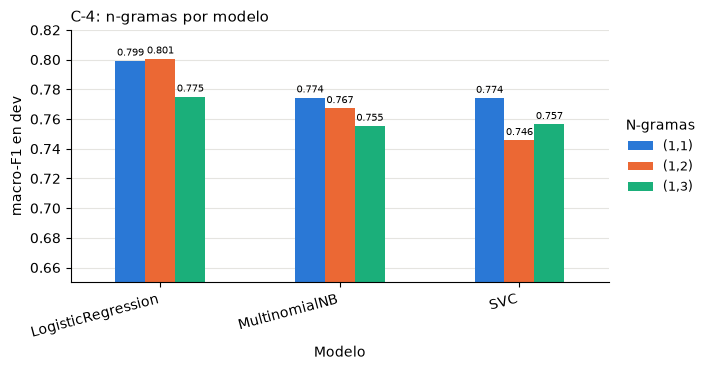

In [5]:
pivot = table.pivot(index="Modelo", columns="N-gramas",
                     values="Dev macro-F1")[["(1,1)", "(1,2)", "(1,3)"]]
ax = pivot.plot(kind="bar", figsize=(7.2, 3.8),
                color=["#2a78d6", "#eb6834", "#1baf7a"])
ax.set_ylim(0.65, 0.82)
ax.set_ylabel("macro-F1 en dev")
ax.set_title("C-4: n-gramas por modelo", loc="left", fontsize=11)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False,
          title="N-gramas", fontsize=9)
ax.set_xticklabels(pivot.index, rotation=15, ha="right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=7)
plt.tight_layout()
plt.show()

## 2. Lectura

- **No hay mejora material.** LR con bigramas obtiene 0.8007 frente a 0.7993 de unigramas:
  0.0014, una décima de documento. Con trigramas baja a 0.7751.
- **NB empeora** con bigramas (0.7673) y trigramas (0.7554) frente a 0.7745 de unigramas.
- **SVC también empeora**: 0.7458 con bigramas y 0.7566 con trigramas frente a 0.7742.
- El vocabulario crece mucho (SVC pasa de 9 974 a 65 935 y 145 406 rasgos), pero el corpus
  es pequeño; los n-gramas añaden dispersión sin señal suficiente.
- **Selección para C-5:** se mantiene la configuración de C-3. En LR, C18 (bigramas) gana
  por 0.0014 pero tiene menor CV (0.7656 frente a 0.7675); por la regla de empate se elige
  C02 (unigramas). En NB y SVC, (1,1) gana claramente.